In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

## Integration über Einheitskreis
Unser Ziel ist es, eine Funktion f über dem Einheitskreis zu integrieren. 

Wir definieren:
- $f$: funktion
- $n$: Anzahl Stützstellen
- `rng`: Random number generator

In [2]:
f = lambda x, y: 1 - x**2 - y**2
n = 500
rng = np.random.default_rng(seed=42)

Jetzt bestimmen wir die Stützstellen, indem wir deren x, y zufällig streuen. Unsere Quadratur verwendet eine Formel, um auf einem Kreis gleichverteilt 2D-Punkte zu generieren. 

In [3]:
u, v = rng.random(size=n), rng.random(size=n)
r, theta = np.sqrt(u), 2*np.pi*v
x, y = r*np.cos(theta), r*np.sin(theta)

# Quadratur:
z = f(x, y)
Q = np.sum(z) / n * np.pi

Nun vergleichen wir unsere Annäherung $Q$ mit dem von Scipy angenäherten Integral:

In [4]:
# Mit scipy
lower, upper = lambda x: -1+x**2, lambda x: 1-x**2
I = scipy.integrate.dblquad(f, -1, 1, lower, upper)[0]

print(f"scipy =\t{I}\nours =\t{Q}")

scipy =	1.523809523809524
ours =	1.5843638039989045


Wir sehen, dass unser Resultat um einiges ungenauer ist als andere Quadraturmethoden. Dies liegt an der Konvergenzrate von:

$$
E(n)=\mathcal{O}(\sqrt{n})
$$

Allerdings bleibt diese für beliebige $d$-dimensionale integrale gleich. 

Der nächste Block plottet noch eine Visualisierung der Quadratur-Stützstellen:

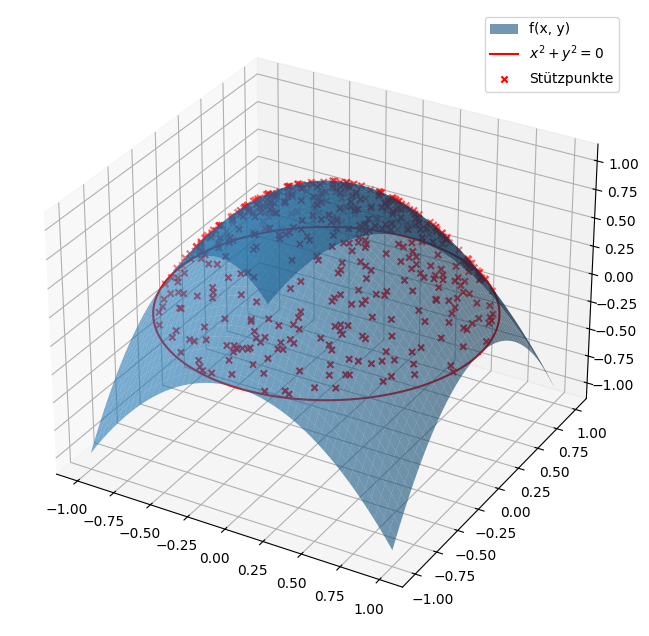

In [5]:
N = 500
a, b = -1, 1
X_,Y_= np.linspace(a, b, N), np.linspace(a, b, N)
X, Y = np.meshgrid(X_, Y_)
Z = f(X, Y)

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")
phi = np.linspace(0, 2*np.pi, N)
ax.plot_surface(X, Y, Z, alpha=0.6, edgecolor="none", label="f(x, y)")
ax.plot(np.cos(phi), np.sin(phi), np.zeros(N), label=r"$x^2+y^2=0$", color="red")
ax.scatter(x, y, f(x, y), label="Stützpunkte", color="red", marker="x")
ax.legend()